# Blood Cell Classification
# MLP vs CNN Comparison

This notebook implements blood cell image classification using both Fully Connected (MLP) and Convolutional Neural Network (CNN) architectures, then compares their performance.

## Setup and Imports

In [1]:
import sys
print(sys.executable)

In [2]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset, random_split
import torchvision.transforms as transforms
from torchvision.datasets import ImageFolder

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix
from PIL import Image
import os
import copy

np.random.seed(42)
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {device}')

Using device: cpu


In [3]:
# Set dataset path - the dataset is in the archive/ folder in the project directory
# For Colab: upload the archive folder or adjust the path
# Dataset: Blood Cell Images for Cancer Detection (5000 images, 5 classes)
# Structure:
# archive/
#   basophil/
#   erythroblast/
#   monocyte/
#   myeloblast/
#   seg_neutrophil/

DATASET_PATH = './archive'  # Dataset path
IMG_SIZE = 64
BATCH_SIZE = 32
NUM_CLASSES = 5
NUM_EPOCHS = 80
LEARNING_RATE = 0.001

class_names = ['basophil', 'erythroblast', 'monocyte', 'myeloblast', 'seg_neutrophil']

for cls in class_names:
    cls_path = os.path.join(DATASET_PATH, cls)
    if os.path.exists(cls_path):
        count = len([f for f in os.listdir(cls_path) if f.endswith(('.jpg', '.png', '.jpeg'))])
        print(f'{cls}: {count} images')
    else:
        print(f'{cls}: NOT FOUND at {cls_path}')
print(f'\nTotal dataset path: {os.path.abspath(DATASET_PATH)}')

basophil: 1000 images
erythroblast: 1000 images
monocyte: 1000 images
myeloblast: 1000 images
seg_neutrophil: 460 images

Total dataset path: C:\Users\Asus\AppData\Local\Temp\opencode\ca5_run\archive


In [4]:
# Define transforms
# We use two transform pipelines:
# 1. train_transform: with augmentation for training
# 2. basic_transform: without augmentation for test/visualization

basic_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),  # Converts to [0,1] and CHW format
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

# For display: convert tensor back to image-friendly format
inv_normalize = transforms.Normalize(
    mean=[-0.485/0.229, -0.456/0.224, -0.406/0.225],
    std=[1/0.229, 1/0.224, 1/0.225]
)

In [5]:
# Load full dataset with basic transform first (for train/test split)
full_dataset = ImageFolder(root=DATASET_PATH, transform=basic_transform)

# Split into train and test (80/20 split)
train_size = int(0.8 * len(full_dataset))
test_size = len(full_dataset) - train_size

train_dataset, test_dataset = random_split(full_dataset, [train_size, test_size],
                                            generator=torch.Generator().manual_seed(42))

# Create DataLoaders
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

print(f'Total dataset size: {len(full_dataset)}')
print(f'Training set size: {len(train_dataset)}')
print(f'Test set size: {len(test_dataset)}')
print(f'Number of classes: {NUM_CLASSES}')
print(f'Class names: {full_dataset.classes}')

Total dataset size: 4460
Training set size: 3568
Test set size: 892
Number of classes: 5
Class names: ['basophil', 'erythroblast', 'monocyte', 'myeloblast', 'seg_neutrophil']


### Why Normalization?
Normalization scales pixel values (originally 0-255) to a standard range. Without normalization:
- Large input values cause large gradients, leading to unstable training
- Different features (R, G, B channels) have different scales, slowing convergence
- Gradient descent takes much longer to find the optimal weights

### Why DataLoader instead of Dataset?
DataLoader provides:
- **Batching**: Automatically splits data into mini-batches for efficient training
- **Shuffling**: Randomizes data order each epoch to prevent order-dependent learning
- **Parallel loading**: Uses multiple workers to preload data, reducing GPU idle time
- **Pin memory**: Speeds up CPU-to-GPU transfer

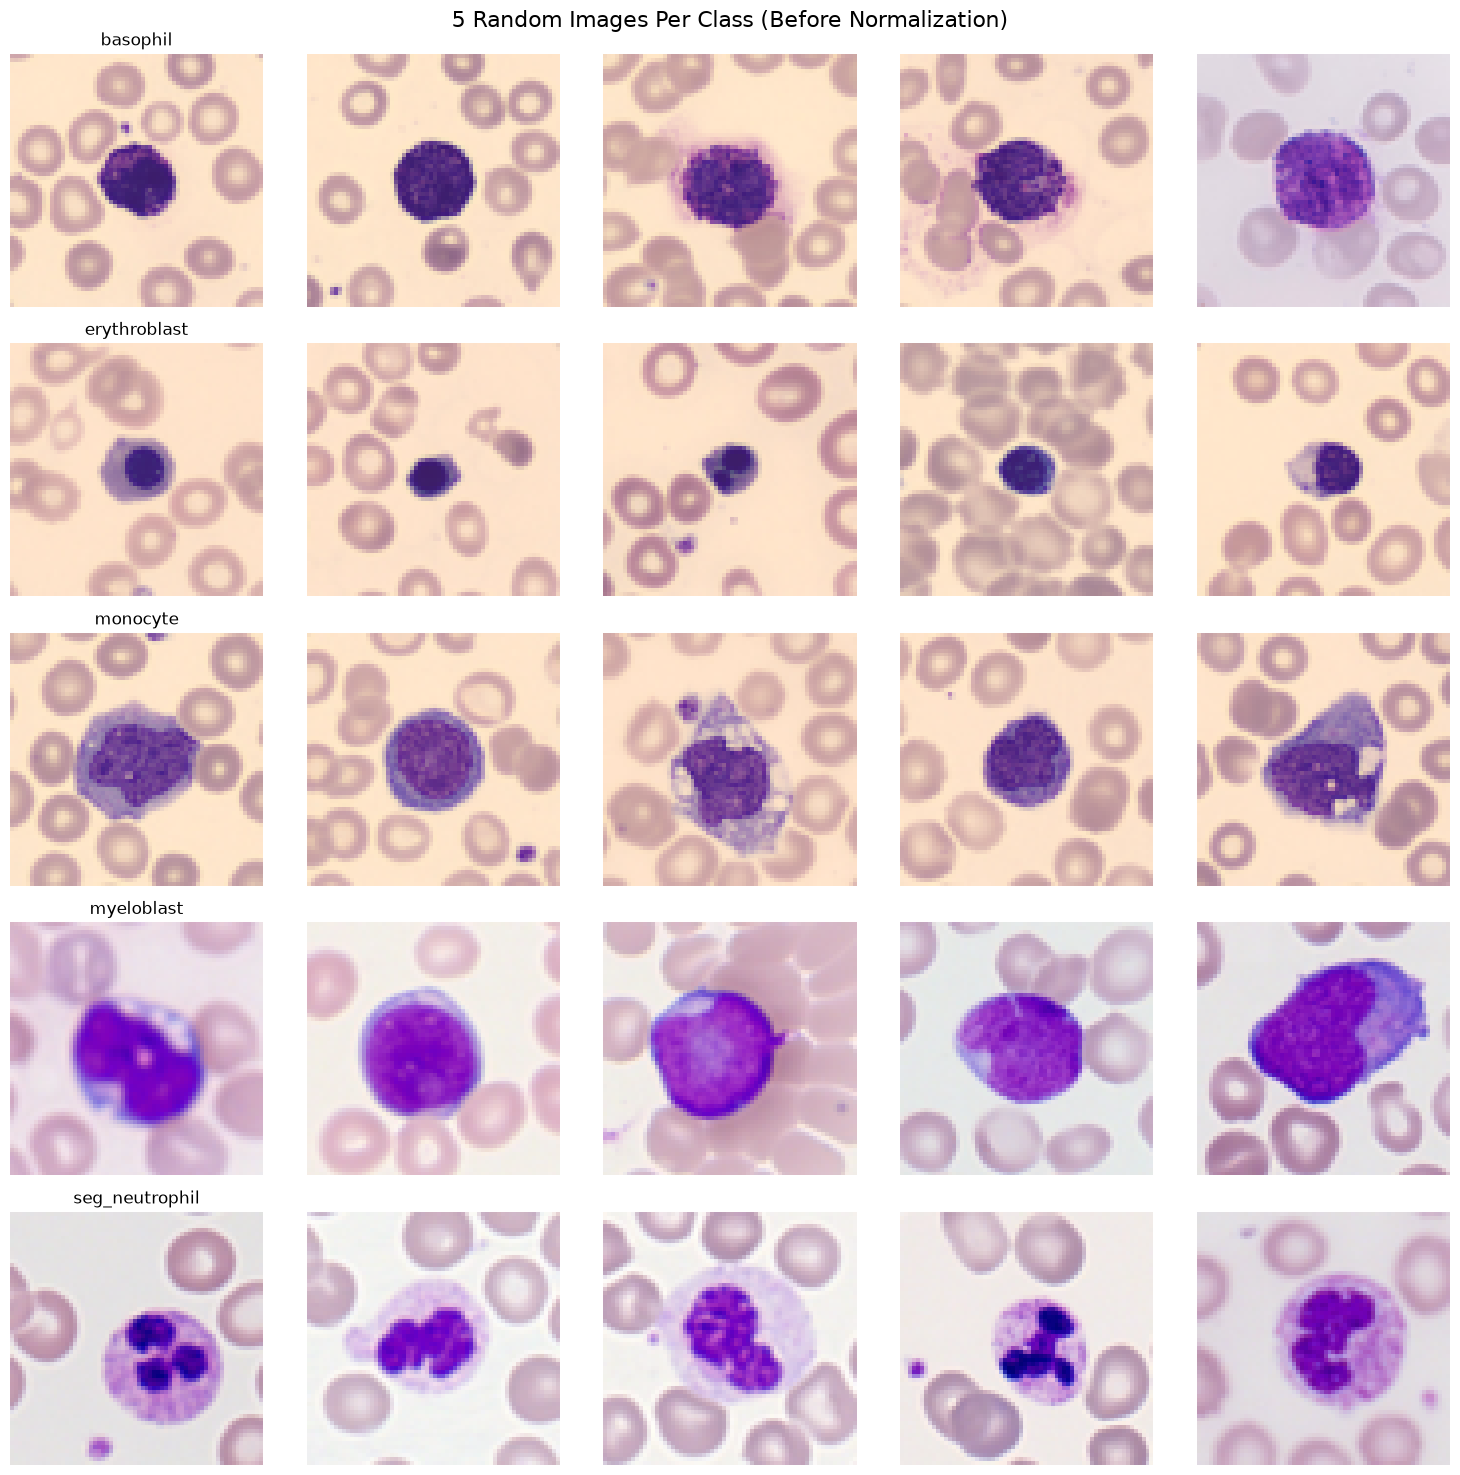

In [6]:
# Show 5 random images per class BEFORE normalization
# We load raw images without normalization for visualization

viz_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor()
])

viz_dataset = ImageFolder(root=DATASET_PATH, transform=viz_transform)

fig, axes = plt.subplots(NUM_CLASSES, 5, figsize=(15, 15))
fig.suptitle('5 Random Images Per Class (Before Normalization)', fontsize=16)

for class_idx in range(NUM_CLASSES):
    # Get indices of all images for this class
    class_indices = [i for i, (_, label) in enumerate(viz_dataset.samples) if label == class_idx]
    # Pick 5 random indices
    chosen = np.random.choice(class_indices, 5, replace=False)
    
    for j, idx in enumerate(chosen):
        img, label = viz_dataset[idx]
        img = img.permute(1, 2, 0).numpy()  # CHW -> HWC
        axes[class_idx, j].imshow(img)
        axes[class_idx, j].axis('off')
        if j == 0:
            axes[class_idx, j].set_title(class_names[label], fontsize=12)

plt.tight_layout()
plt.show()

---
## Part 1: Fully Connected Neural Network (MLP)

In [7]:
class BloodCellMLP(nn.Module):
    """
    Fully Connected Neural Network for Blood Cell Classification.
    Input: 64x64x3 = 12288 (flattened image)
    Output: 5 classes
    
    Architecture:
    Input(12288) -> FC(1024) -> ReLU -> Dropout(0.5) -> 
    FC(512) -> ReLU -> Dropout(0.5) -> 
    FC(256) -> ReLU -> Dropout(0.3) -> 
    FC(128) -> ReLU -> Dropout(0.2) -> 
    FC(5)
    
    Parameter count calculation:
    Layer 1: 12288*1024 + 1024 = 12,583,936
    ... this is too many. Let's use a smaller architecture.
    
    With ~3.5M params:
    Layer 1: 12288*256 + 256 = 3,145,984
    Layer 2: 256*128 + 128 = 32,896
    Layer 3: 128*64 + 64 = 8,256
    Layer 4: 64*5 + 5 = 325
    Total: ~3,187,461
    """
    def __init__(self):
        super(BloodCellMLP, self).__init__()
        input_size = IMG_SIZE * IMG_SIZE * 3  # 64*64*3 = 12288
        
        self.flatten = nn.Flatten()
        self.network = nn.Sequential(
            nn.Linear(input_size, 256),   
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(256, 128),           
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, 64),            
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(64, NUM_CLASSES)     
        )
    
    def forward(self, x):
        x = self.flatten(x)
        x = self.network(x)
        return x

# Create model instance
mlp_model = BloodCellMLP().to(device)

# Count parameters
mlp_params = sum(p.numel() for p in mlp_model.parameters() if p.requires_grad)
print(f'MLP Model Architecture:')
print(mlp_model)
print(f'\nTrainable parameters: {mlp_params:,}')
print(f'\nManual parameter calculation:')
print(f'  Layer 1 (Linear): {IMG_SIZE*IMG_SIZE*3}*256 + 256 = {IMG_SIZE*IMG_SIZE*3*256 + 256:,}')
print(f'  Layer 2 (Linear): 256*128 + 128 = {256*128 + 128:,}')
print(f'  Layer 3 (Linear): 128*64 + 64 = {128*64 + 64:,}')
print(f'  Layer 4 (Linear): 64*5 + 5 = {64*5 + 5:,}')
print(f'  Total: {IMG_SIZE*IMG_SIZE*3*256 + 256 + 256*128 + 128 + 128*64 + 64 + 64*5 + 5:,}')

MLP Model Architecture:
BloodCellMLP(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (network): Sequential(
    (0): Linear(in_features=12288, out_features=256, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.5, inplace=False)
    (3): Linear(in_features=256, out_features=128, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.3, inplace=False)
    (6): Linear(in_features=128, out_features=64, bias=True)
    (7): ReLU()
    (8): Dropout(p=0.2, inplace=False)
    (9): Linear(in_features=64, out_features=5, bias=True)
  )
)

Trainable parameters: 3,187,461

Manual parameter calculation:
  Layer 1 (Linear): 12288*256 + 256 = 3,145,984
  Layer 2 (Linear): 256*128 + 128 = 32,896
  Layer 3 (Linear): 128*64 + 64 = 8,256
  Layer 4 (Linear): 64*5 + 5 = 325
  Total: 3,187,461


In [8]:
# Loss function and optimizer
# CrossEntropyLoss: combines LogSoftmax and NLLLoss, ideal for multi-class classification
# Adam optimizer: adaptive learning rate, generally converges faster than SGD

criterion = nn.CrossEntropyLoss()
optimizer_mlp = optim.Adam(mlp_model.parameters(), lr=LEARNING_RATE)

In [9]:
def train_model(model, train_loader, test_loader, criterion, optimizer, num_epochs, model_name="Model"):
    """
    Train a model and return training history.
    
    Returns:
        history: dict with 'train_loss' and 'test_loss' per epoch
    """
    history = {'train_loss': [], 'test_loss': []}
    best_model_wts = copy.deepcopy(model.state_dict())
    best_acc = 0.0
    
    for epoch in range(num_epochs):
        # Training phase
        model.train()
        running_train_loss = 0.0
        correct = 0
        total = 0
        
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            
            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            
            running_train_loss += loss.item() * images.size(0)
            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
        
        train_loss = running_train_loss / len(train_loader.dataset)
        train_acc = 100.0 * correct / total
        
        # Testing phase
        model.eval()
        running_test_loss = 0.0
        correct = 0
        total = 0
        
        with torch.no_grad():
            for images, labels in test_loader:
                images, labels = images.to(device), labels.to(device)
                outputs = model(images)
                loss = criterion(outputs, labels)
                
                running_test_loss += loss.item() * images.size(0)
                _, predicted = torch.max(outputs.data, 1)
                total += labels.size(0)
                correct += (predicted == labels).sum().item()
        
        test_loss = running_test_loss / len(test_loader.dataset)
        test_acc = 100.0 * correct / total
        
        history['train_loss'].append(train_loss)
        history['test_loss'].append(test_loss)
        
        print(f'[{model_name}] Epoch [{epoch+1}/{num_epochs}] '
              f'Train Loss: {train_loss:.4f} | Test Loss: {test_loss:.4f} '
              f'| Train Acc: {train_acc:.2f}% | Test Acc: {test_acc:.2f}%')
        
        if test_acc > best_acc:
            best_acc = test_acc
            best_model_wts = copy.deepcopy(model.state_dict())
    
    model.load_state_dict(best_model_wts)
    print(f'\n[{model_name}] Best Test Accuracy: {best_acc:.2f}%')
    return history

In [10]:
# Train MLP model
print('Training MLP Model...')
print('='*60)
mlp_history = train_model(mlp_model, train_loader, test_loader,
                          criterion, optimizer_mlp, NUM_EPOCHS, "MLP")

Training MLP Model...
[MLP] Epoch [1/80] Train Loss: 1.3869 | Test Loss: 0.7276 | Train Acc: 41.15% | Test Acc: 72.00%
[MLP] Epoch [2/80] Train Loss: 0.8873 | Test Loss: 0.7065 | Train Acc: 59.35% | Test Acc: 67.60%
[MLP] Epoch [3/80] Train Loss: 0.8165 | Test Loss: 0.5970 | Train Acc: 64.17% | Test Acc: 81.10%
[MLP] Epoch [4/80] Train Loss: 0.8142 | Test Loss: 0.5859 | Train Acc: 64.20% | Test Acc: 77.50%
[MLP] Epoch [5/80] Train Loss: 0.8222 | Test Loss: 0.6818 | Train Acc: 62.92% | Test Acc: 81.20%
[MLP] Epoch [6/80] Train Loss: 0.8165 | Test Loss: 0.6461 | Train Acc: 62.90% | Test Acc: 73.20%
[MLP] Epoch [7/80] Train Loss: 0.7800 | Test Loss: 0.5716 | Train Acc: 66.78% | Test Acc: 84.70%
[MLP] Epoch [8/80] Train Loss: 0.7206 | Test Loss: 0.5494 | Train Acc: 69.25% | Test Acc: 83.40%
[MLP] Epoch [9/80] Train Loss: 0.7283 | Test Loss: 0.5764 | Train Acc: 68.80% | Test Acc: 75.60%
[MLP] Epoch [10/80] Train Loss: 0.7082 | Test Loss: 0.5799 | Train Acc: 68.58% | Test Acc: 84.50%
[MLP] E

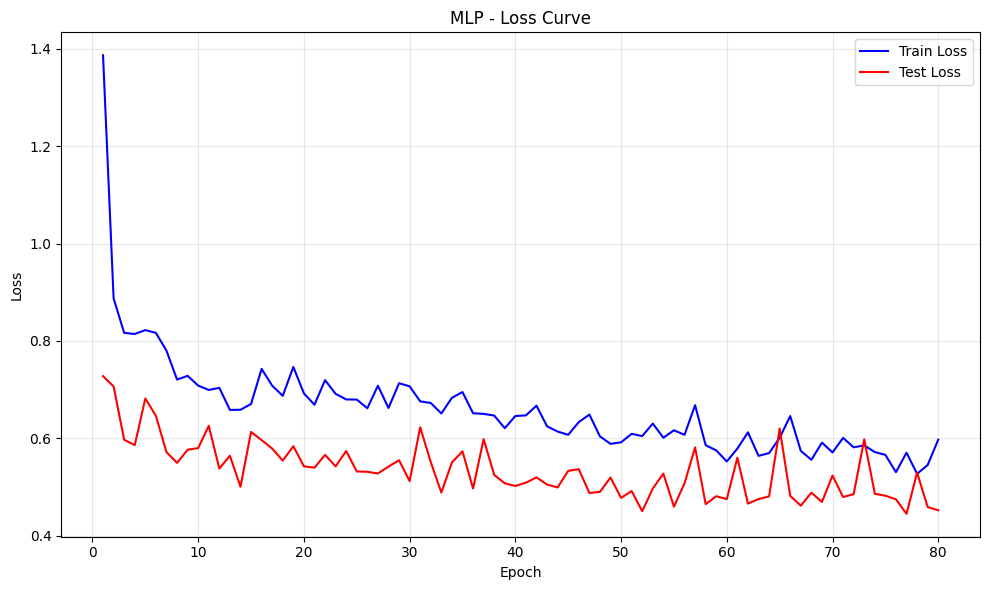


--- MLP Loss Curve Analysis ---
Final Train Loss: 0.5971
Final Test Loss: 0.4521
No significant overfitting detected.


In [11]:
# Plot Loss Curves for MLP
fig, ax = plt.subplots(1, 1, figsize=(10, 6))
ax.plot(range(1, NUM_EPOCHS + 1), mlp_history['train_loss'], label='Train Loss', color='blue')
ax.plot(range(1, NUM_EPOCHS + 1), mlp_history['test_loss'], label='Test Loss', color='red')
ax.set_xlabel('Epoch')
ax.set_ylabel('Loss')
ax.set_title('MLP - Loss Curve')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Analysis:
print('\n--- MLP Loss Curve Analysis ---')
final_train = mlp_history['train_loss'][-1]
final_test = mlp_history['test_loss'][-1]
print(f'Final Train Loss: {final_train:.4f}')
print(f'Final Test Loss: {final_test:.4f}')
if final_test > final_train * 1.3:
    print('Overfitting detected: Test loss is significantly higher than train loss.')
    print('This suggests the model memorizes training data but generalizes poorly.')
else:
    print('No significant overfitting detected.')

In [12]:
# Evaluate MLP on test set
def evaluate_model(model, test_loader, class_names):
    """Evaluate model and return predictions, true labels, and softmax probabilities."""
    model.eval()
    all_preds = []
    all_labels = []
    all_probs = []
    all_images = []
    
    with torch.no_grad():
        for images, labels in test_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            probs = torch.softmax(outputs, dim=1)
            _, preds = torch.max(outputs, 1)
            
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
            all_probs.extend(probs.cpu().numpy())
            all_images.extend(images.cpu())
    
    return np.array(all_preds), np.array(all_labels), np.array(all_probs), all_images

mlp_preds, mlp_true, mlp_probs, mlp_images = evaluate_model(mlp_model, test_loader, class_names)

print('MLP Classification Report:')
print(classification_report(mlp_true, mlp_preds, target_names=class_names))

MLP Classification Report:
                precision    recall  f1-score   support

      basophil       0.82      0.85      0.83       178
  erythroblast       0.98      0.85      0.91       200
      monocyte       0.86      0.87      0.86       224
    myeloblast       0.96      0.88      0.92       201
seg_neutrophil       0.81      0.95      0.87       197

      accuracy                           0.88      1000
     macro avg       0.89      0.88      0.88      1000
  weighted avg       0.89      0.88      0.88      1000



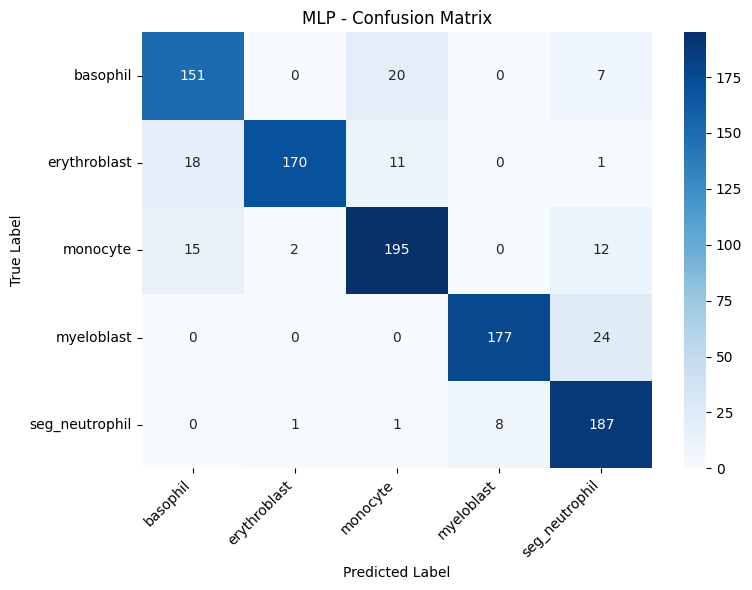

In [13]:
# Confusion Matrix for MLP
cm_mlp = confusion_matrix(mlp_true, mlp_preds)
plt.figure(figsize=(8, 6))
sns.heatmap(cm_mlp, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.title('MLP - Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

### MLP Analysis

**Dropout**: Randomly deactivates neurons during training (with probability p), forcing the network to learn redundant representations. This prevents co-adaptation of neurons and acts as a form of regularization.

**CrossEntropyLoss**: Combines `nn.LogSoftmax()` and `nn.NLLLoss()`. Ideal for multi-class classification because it penalizes confident wrong predictions more heavily, outputting a probability distribution over classes.

**Adam Optimizer**: Computes adaptive learning rates for each parameter using first and second moment estimates. Key differences from SGD:
- SGD uses a single learning rate for all parameters; Adam adapts per-parameter
- Adam includes momentum (first moment) and RMSprop (second moment)
- Adam converges faster but may generalize slightly worse than well-tuned SGD+momentum

---
## Part 2: Convolutional Neural Network (CNN)

In [14]:
class CNN(nn.Module):
    """
    Convolutional Neural Network for Blood Cell Classification.
    Designed to have approximately the same number of parameters as the MLP.
    
    Architecture:
    Conv2d(3, 16, 3, padding=1) -> ReLU -> MaxPool(2)    # 64x64 -> 32x32
    Conv2d(16, 32, 3, padding=1) -> ReLU -> MaxPool(2)   # 32x32 -> 16x16
    Conv2d(32, 64, 3, padding=1) -> ReLU -> MaxPool(2)   # 16x16 -> 8x8
    Flatten -> Linear(64*8*8, 256) -> ReLU -> Dropout(0.5)
    Linear(256, 128) -> ReLU -> Dropout(0.3)
    Linear(128, 5)
    
    Parameter count:
    Conv1: 3*16*3*3 + 16 = 448
    Conv2: 16*32*3*3 + 32 = 4,640
    Conv3: 32*64*3*3 + 64 = 18,496
    FC1: 4096*256 + 256 = 1,048,832
    FC2: 256*128 + 128 = 32,896
    FC3: 128*5 + 5 = 645
    Total: ~1,105,957
    
    Let's increase to match ~3.18M params:
    Conv1: 3*32*3*3 + 32 = 896
    Conv2: 32*64*3*3 + 64 = 18,496
    Conv3: 64*128*3*3 + 128 = 73,856
    FC1: 8192*256 + 256 = 2,097,408
    FC2: 256*128 + 128 = 32,896
    FC3: 128*5 + 5 = 645
    Total: ~2,224,197
    
    Need a bit more. Use 512 in FC1:
    FC1: 8192*512 + 512 = 4,194,816 -> too many
    FC1: 8192*384 + 384 = 3,146,112
    FC2: 384*128 + 128 = 49,280
    FC3: 128*5 + 5 = 645
    Total: ~3,146,112 + 73,856 + 18,496 + 896 + 49,280 + 645 = ~3,289,285
    """
    def __init__(self):
        super(CNN, self).__init__()
        
        self.conv_layers = nn.Sequential(
            # Conv Block 1: 3 -> 32 channels, 64x64 -> 32x32
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),
            
            # Conv Block 2: 32 -> 64 channels, 32x32 -> 16x16
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),
            
            # Conv Block 3: 64 -> 128 channels, 16x16 -> 8x8
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),
        )
        
        self.fc_layers = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 8 * 8, 384),  # 8192 -> 384
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(384, 128),           # 384 -> 128
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, NUM_CLASSES)    # 128 -> 5
        )
    
    def forward(self, x):
        x = self.conv_layers(x)
        x = self.fc_layers(x)
        return x

# Create CNN model instance
cnn_model = CNN().to(device)

# Count parameters
cnn_params = sum(p.numel() for p in cnn_model.parameters() if p.requires_grad)
print(f'CNN Model Architecture:')
print(cnn_model)
print(f'\nTrainable parameters: {cnn_params:,}')
print(f'\nManual parameter calculation:')
print(f'  Conv1: 3*32*3*3 + 32 = {3*32*3*3 + 32:,}')
print(f'  Conv2: 32*64*3*3 + 64 = {32*64*3*3 + 64:,}')
print(f'  Conv3: 64*128*3*3 + 128 = {64*128*3*3 + 128:,}')
print(f'  BN1 params: {32*2:,} (running_mean: {32}, running_var: {32}, weight: {32}, bias: {32})')
print(f'  BN2 params: {64*2:,} (running_mean: {64}, running_var: {64}, weight: {64}, bias: {64})')
print(f'  BN3 params: {128*2:,} (running_mean: {128}, running_var: {128}, weight: {128}, bias: {128})')
print(f'  FC1: 8192*384 + 384 = {8192*384 + 384:,}')
print(f'  FC2: 384*128 + 128 = {384*128 + 128:,}')
print(f'  FC3: 128*5 + 5 = {128*5 + 5:,}')
manual_total = (3*32*3*3 + 32) + (32*64*3*3 + 64) + (64*128*3*3 + 128) + \
                (32*4) + (64*4) + (128*4) + \
                (8192*384 + 384) + (384*128 + 128) + (128*5 + 5)
print(f'  Total (trainable): {manual_total:,}')

CNN Model Architecture:
CNN(
  (conv_layers): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (fc_layers): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=8192, out_fea

In [15]:
# Loss function and optimizer for CNN
criterion_cnn = nn.CrossEntropyLoss()
optimizer_cnn = optim.Adam(cnn_model.parameters(), lr=LEARNING_RATE)

In [16]:
# Train CNN model
print('Training CNN Model...')
print('='*60)
cnn_history = train_model(cnn_model, train_loader, test_loader,
                          criterion_cnn, optimizer_cnn, NUM_EPOCHS, "CNN")

Training CNN Model...
[CNN] Epoch [1/80] Train Loss: 0.7298 | Test Loss: 0.4140 | Train Acc: 69.90% | Test Acc: 81.10%
[CNN] Epoch [2/80] Train Loss: 0.3335 | Test Loss: 0.2092 | Train Acc: 88.00% | Test Acc: 92.30%
[CNN] Epoch [3/80] Train Loss: 0.2073 | Test Loss: 0.1686 | Train Acc: 92.85% | Test Acc: 94.10%
[CNN] Epoch [4/80] Train Loss: 0.1510 | Test Loss: 0.4178 | Train Acc: 94.92% | Test Acc: 86.40%
[CNN] Epoch [5/80] Train Loss: 0.1358 | Test Loss: 0.1296 | Train Acc: 95.38% | Test Acc: 95.70%
[CNN] Epoch [6/80] Train Loss: 0.1377 | Test Loss: 0.1005 | Train Acc: 95.50% | Test Acc: 97.10%
[CNN] Epoch [7/80] Train Loss: 0.0941 | Test Loss: 0.1867 | Train Acc: 97.00% | Test Acc: 95.00%
[CNN] Epoch [8/80] Train Loss: 0.0827 | Test Loss: 0.2791 | Train Acc: 97.28% | Test Acc: 91.90%
[CNN] Epoch [9/80] Train Loss: 0.0887 | Test Loss: 0.1069 | Train Acc: 97.35% | Test Acc: 96.50%
[CNN] Epoch [10/80] Train Loss: 0.0559 | Test Loss: 0.1224 | Train Acc: 98.33% | Test Acc: 96.40%
[CNN] E

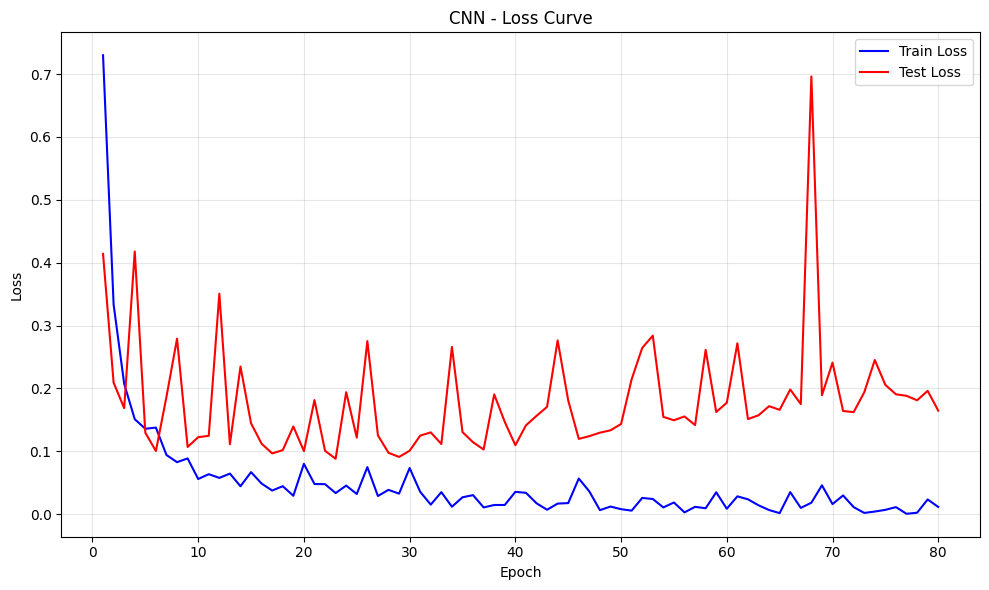

In [17]:
# Plot Loss Curves for CNN
fig, ax = plt.subplots(1, 1, figsize=(10, 6))
ax.plot(range(1, NUM_EPOCHS + 1), cnn_history['train_loss'], label='Train Loss', color='blue')
ax.plot(range(1, NUM_EPOCHS + 1), cnn_history['test_loss'], label='Test Loss', color='red')
ax.set_xlabel('Epoch')
ax.set_ylabel('Loss')
ax.set_title('CNN - Loss Curve')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [18]:
# Evaluate CNN on test set
cnn_preds, cnn_true, cnn_probs, cnn_images = evaluate_model(cnn_model, test_loader, class_names)

print('CNN Classification Report:')
print(classification_report(cnn_true, cnn_preds, target_names=class_names))

CNN Classification Report:
                precision    recall  f1-score   support

      basophil       0.99      0.98      0.99       178
  erythroblast       0.98      0.98      0.98       200
      monocyte       0.98      0.99      0.98       224
    myeloblast       0.99      1.00      1.00       201
seg_neutrophil       1.00      0.99      0.99       197

      accuracy                           0.99      1000
     macro avg       0.99      0.99      0.99      1000
  weighted avg       0.99      0.99      0.99      1000



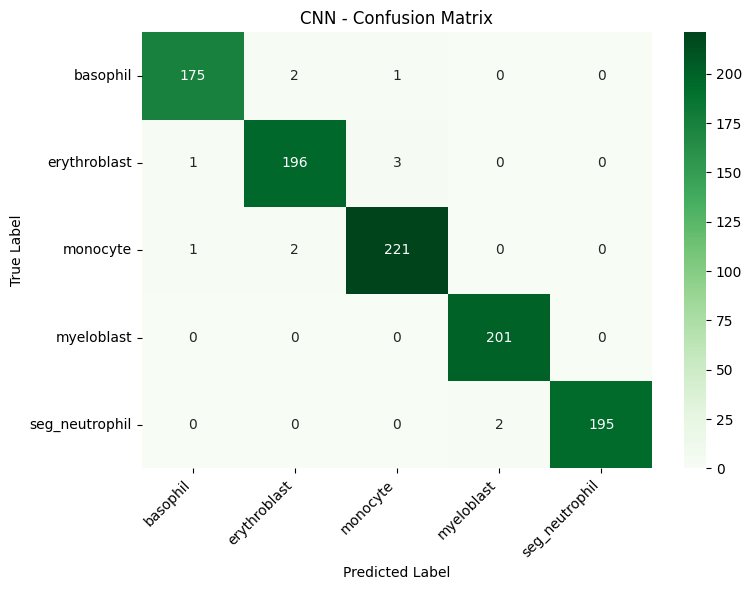

In [19]:
# Confusion Matrix for CNN
cm_cnn = confusion_matrix(cnn_true, cnn_preds)
plt.figure(figsize=(8, 6))
sns.heatmap(cm_cnn, annot=True, fmt='d', cmap='Greens',
            xticklabels=class_names, yticklabels=class_names)
plt.title('CNN - Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

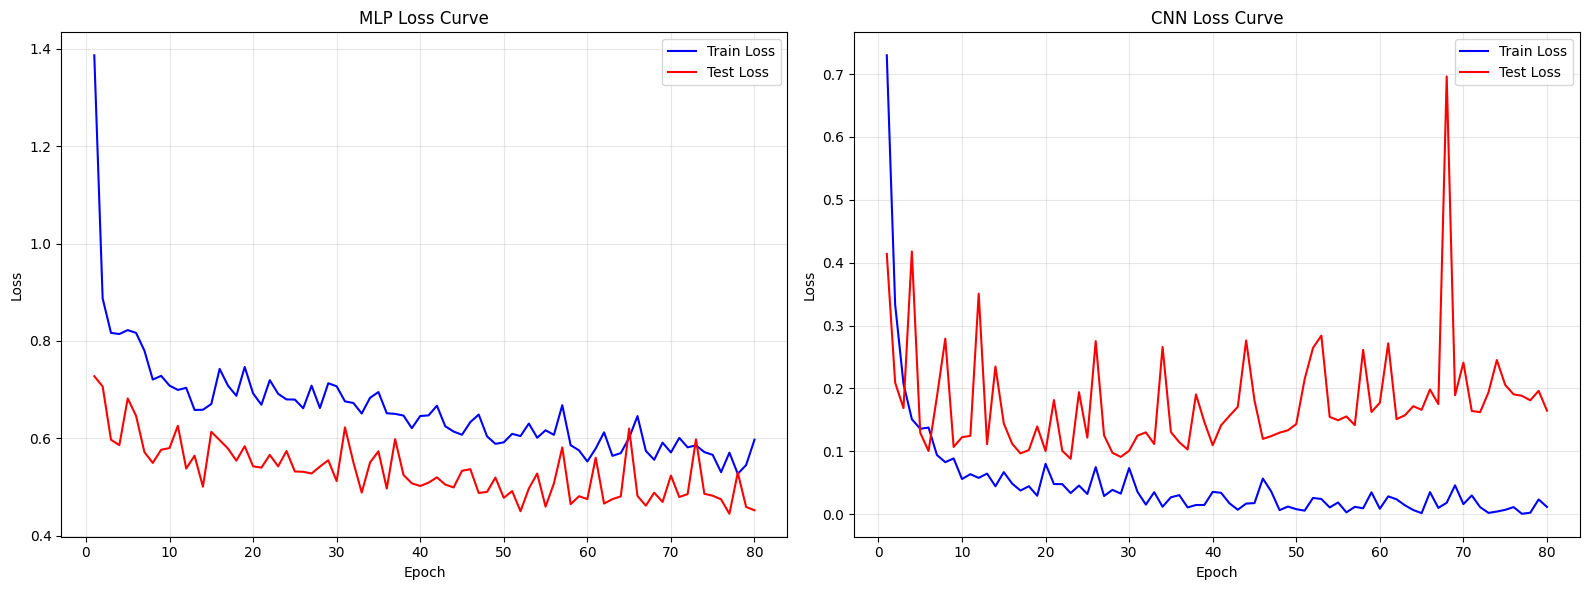


MLP Parameters: 3,187,461
CNN Parameters: 3,289,733

MLP final test loss: 0.4521
CNN final test loss: 0.1646


In [20]:
# Compare MLP and CNN loss curves side by side
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

axes[0].plot(range(1, NUM_EPOCHS + 1), mlp_history['train_loss'], label='Train Loss', color='blue')
axes[0].plot(range(1, NUM_EPOCHS + 1), mlp_history['test_loss'], label='Test Loss', color='red')
axes[0].set_title('MLP Loss Curve')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(range(1, NUM_EPOCHS + 1), cnn_history['train_loss'], label='Train Loss', color='blue')
axes[1].plot(range(1, NUM_EPOCHS + 1), cnn_history['test_loss'], label='Test Loss', color='red')
axes[1].set_title('CNN Loss Curve')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f'\nMLP Parameters: {mlp_params:,}')
print(f'CNN Parameters: {cnn_params:,}')
print(f'\nMLP final test loss: {mlp_history["test_loss"][-1]:.4f}')
print(f'CNN final test loss: {cnn_history["test_loss"][-1]:.4f}')

### CNN Analysis

**Kernel Size Impact**: Smaller kernels (3x3) capture fine-grained local features and are computationally cheaper. Larger kernels capture broader patterns but require more parameters and computation. Modern architectures prefer stacking small kernels.

**Network Depth**: Deeper networks can learn more abstract, hierarchical features (edges -> textures -> parts -> objects). However, very deep networks suffer from vanishing gradients and overfitting. BatchNorm and skip connections help mitigate these issues.

---
## Part 3: Error Analysis and Softmax Output


MLP: Found 120 misclassified images out of 1000


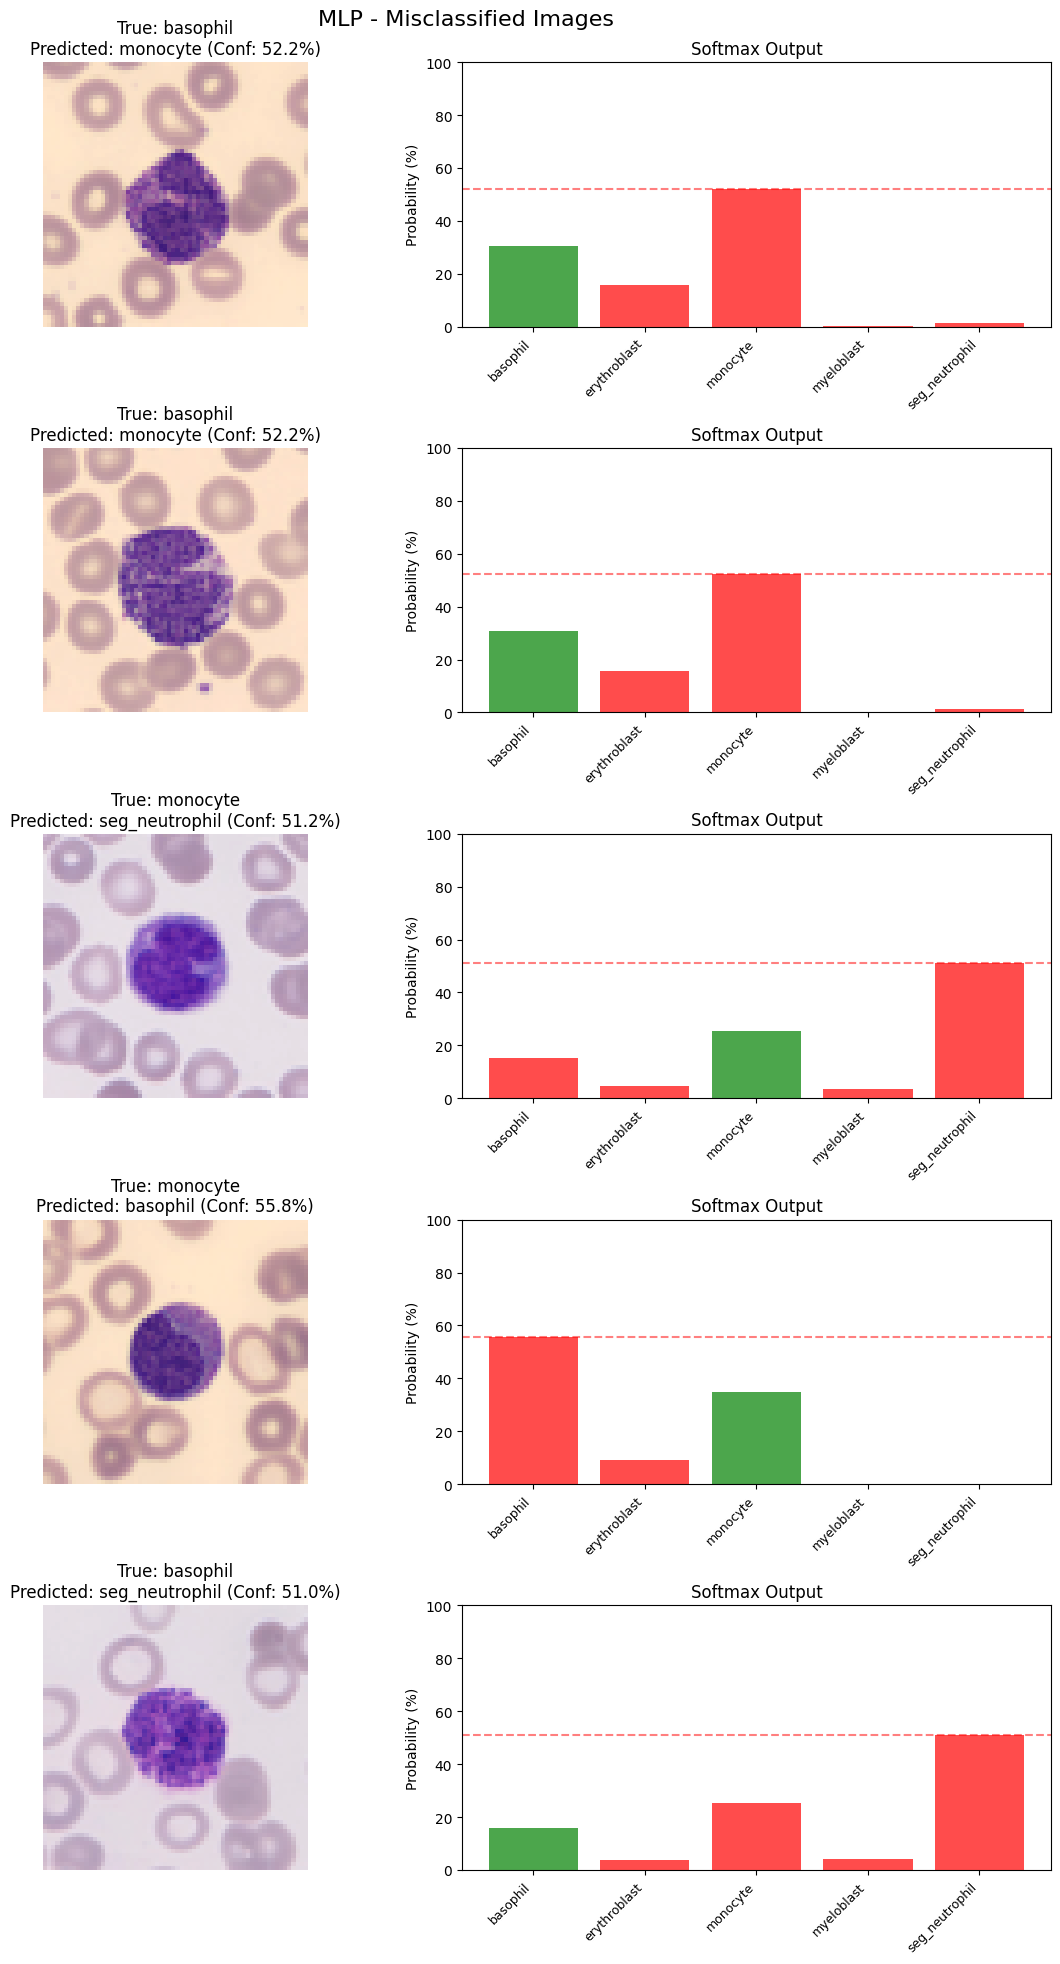

In [21]:
def show_misclassified(model_name, preds, true_labels, probs, images, class_names, num_samples=5):
    """
    Show misclassified images with their predicted and true labels,
    along with softmax probability bar charts.
    """
    # Find misclassified indices
    misclassified_idx = np.where(preds != true_labels)[0]
    print(f'\n{model_name}: Found {len(misclassified_idx)} misclassified images out of {len(true_labels)}')
    
    # Select up to num_samples random misclassified
    if len(misclassified_idx) == 0:
        print('No misclassified images found!')
        return
    
    chosen = np.random.choice(misclassified_idx, min(num_samples, len(misclassified_idx)), replace=False)
    
    fig, axes = plt.subplots(len(chosen), 2, figsize=(12, 4 * len(chosen)))
    if len(chosen) == 1:
        axes = axes.reshape(1, -1)
    
    fig.suptitle(f'{model_name} - Misclassified Images', fontsize=16)
    
    for i, idx in enumerate(chosen):
        # Get image and unnormalize for display
        img = images[idx].clone()
        img = inv_normalize(img)
        img = img.permute(1, 2, 0).numpy()
        img = np.clip(img, 0, 1)
        
        true_class = class_names[true_labels[idx]]
        pred_class = class_names[preds[idx]]
        conf = probs[idx][preds[idx]] * 100
        
        # Show image
        axes[i, 0].imshow(img)
        axes[i, 0].set_title(f'True: {true_class}\nPredicted: {pred_class} (Conf: {conf:.1f}%)')
        axes[i, 0].axis('off')
        
        # Show softmax probability bar chart
        colors = ['green' if j == true_labels[idx] else 'red' for j in range(len(class_names))]
        axes[i, 1].bar(range(len(class_names)), probs[idx] * 100, color=colors, alpha=0.7)
        axes[i, 1].set_xticks(range(len(class_names)))
        axes[i, 1].set_xticklabels(class_names, rotation=45, ha='right', fontsize=9)
        axes[i, 1].set_ylabel('Probability (%)')
        axes[i, 1].set_title('Softmax Output')
        axes[i, 1].set_ylim(0, 100)
        
        # Mark predicted and true
        axes[i, 1].axhline(y=probs[idx][preds[idx]] * 100, color='red', linestyle='--', alpha=0.5)
    
    plt.tight_layout()
    plt.show()

# Show MLP misclassified
show_misclassified('MLP', mlp_preds, mlp_true, mlp_probs, mlp_images, class_names)


CNN: Found 12 misclassified images out of 1000


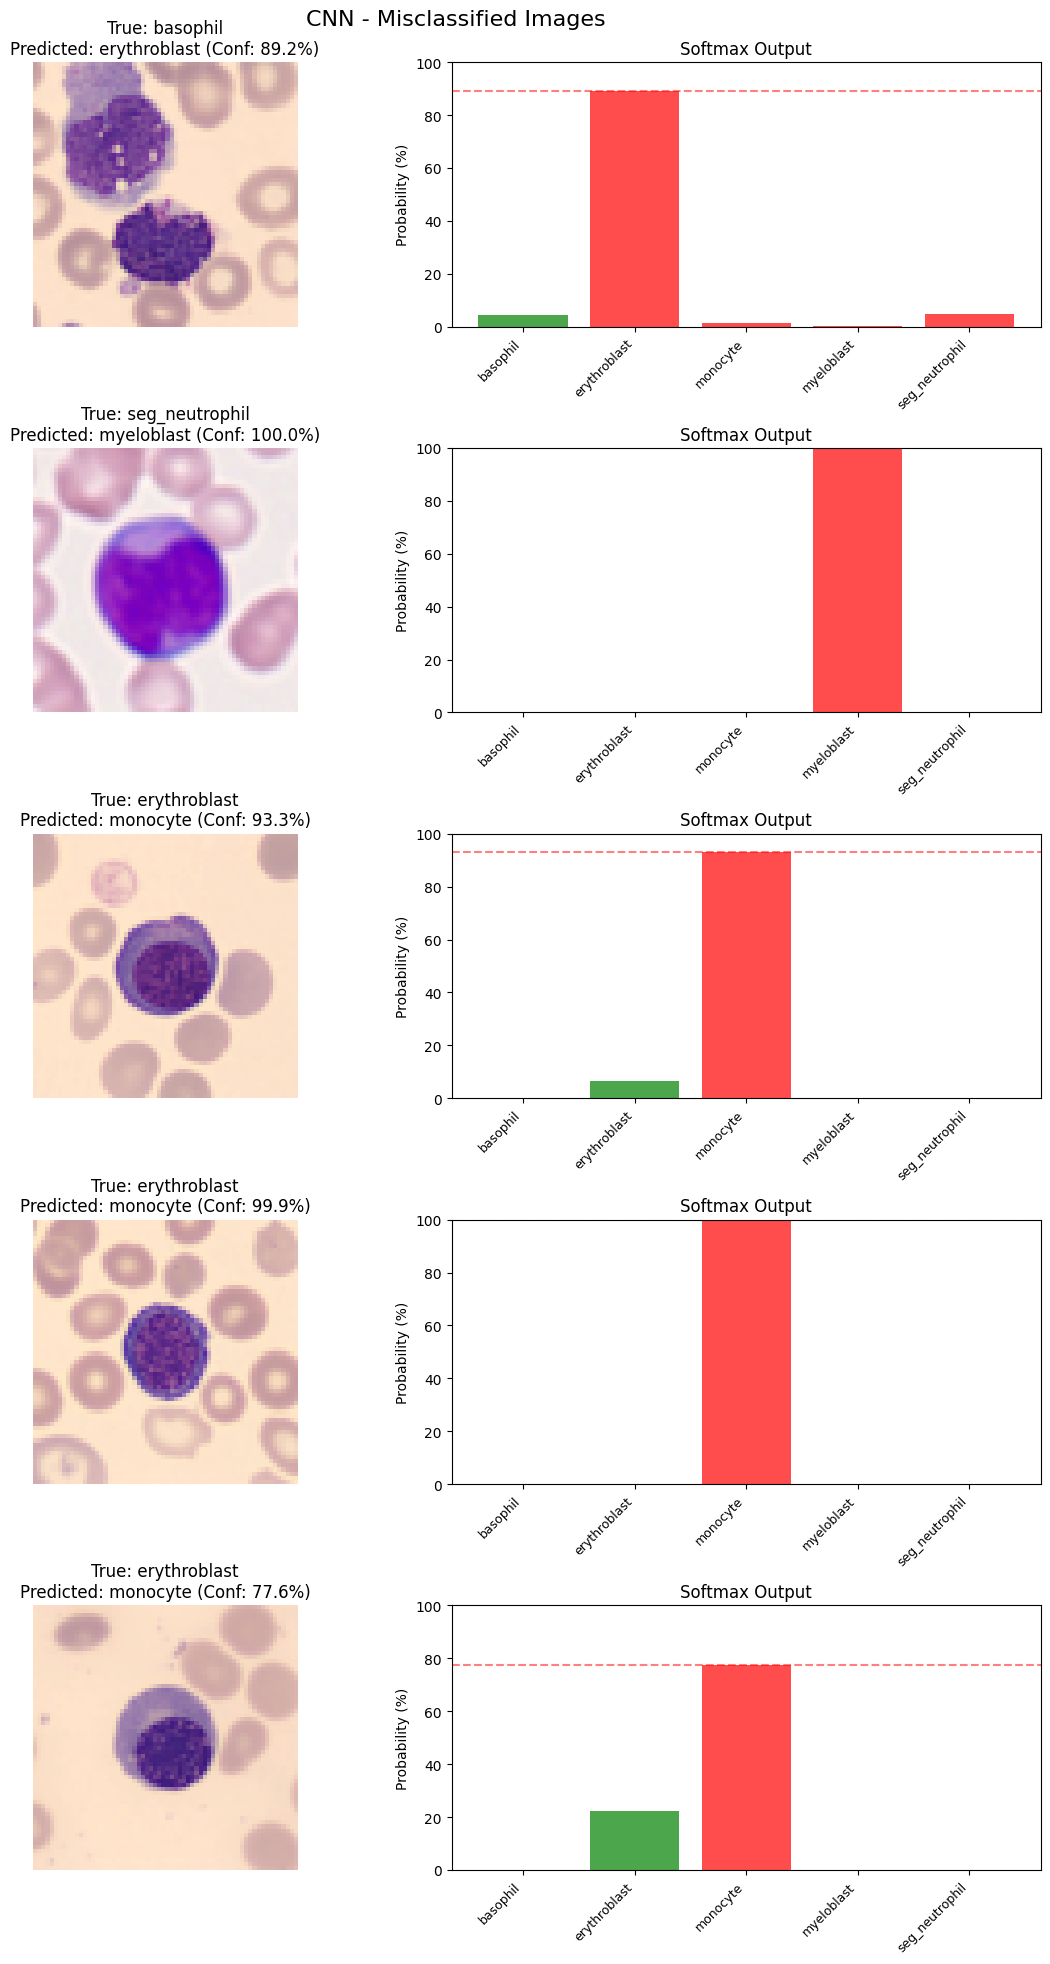

In [22]:
# Show CNN misclassified
show_misclassified('CNN', cnn_preds, cnn_true, cnn_probs, cnn_images, class_names)

### Error Analysis

- **High-confidence errors**: When the model predicts wrong with high probability, it suggests the features of the two classes are very similar (e.g., basophil vs. monocyte may have similar staining patterns).
- **Low-confidence errors**: When probabilities are spread across classes, the model is uncertain, which may indicate ambiguous or noisy images.
- **Visual similarities**: Blood cell types can look very similar under microscope - similar cell sizes, nuclear shapes, and staining patterns cause confusion.

---
## Part 4: Feature Maps Visualization

Visualization for class: monocyte


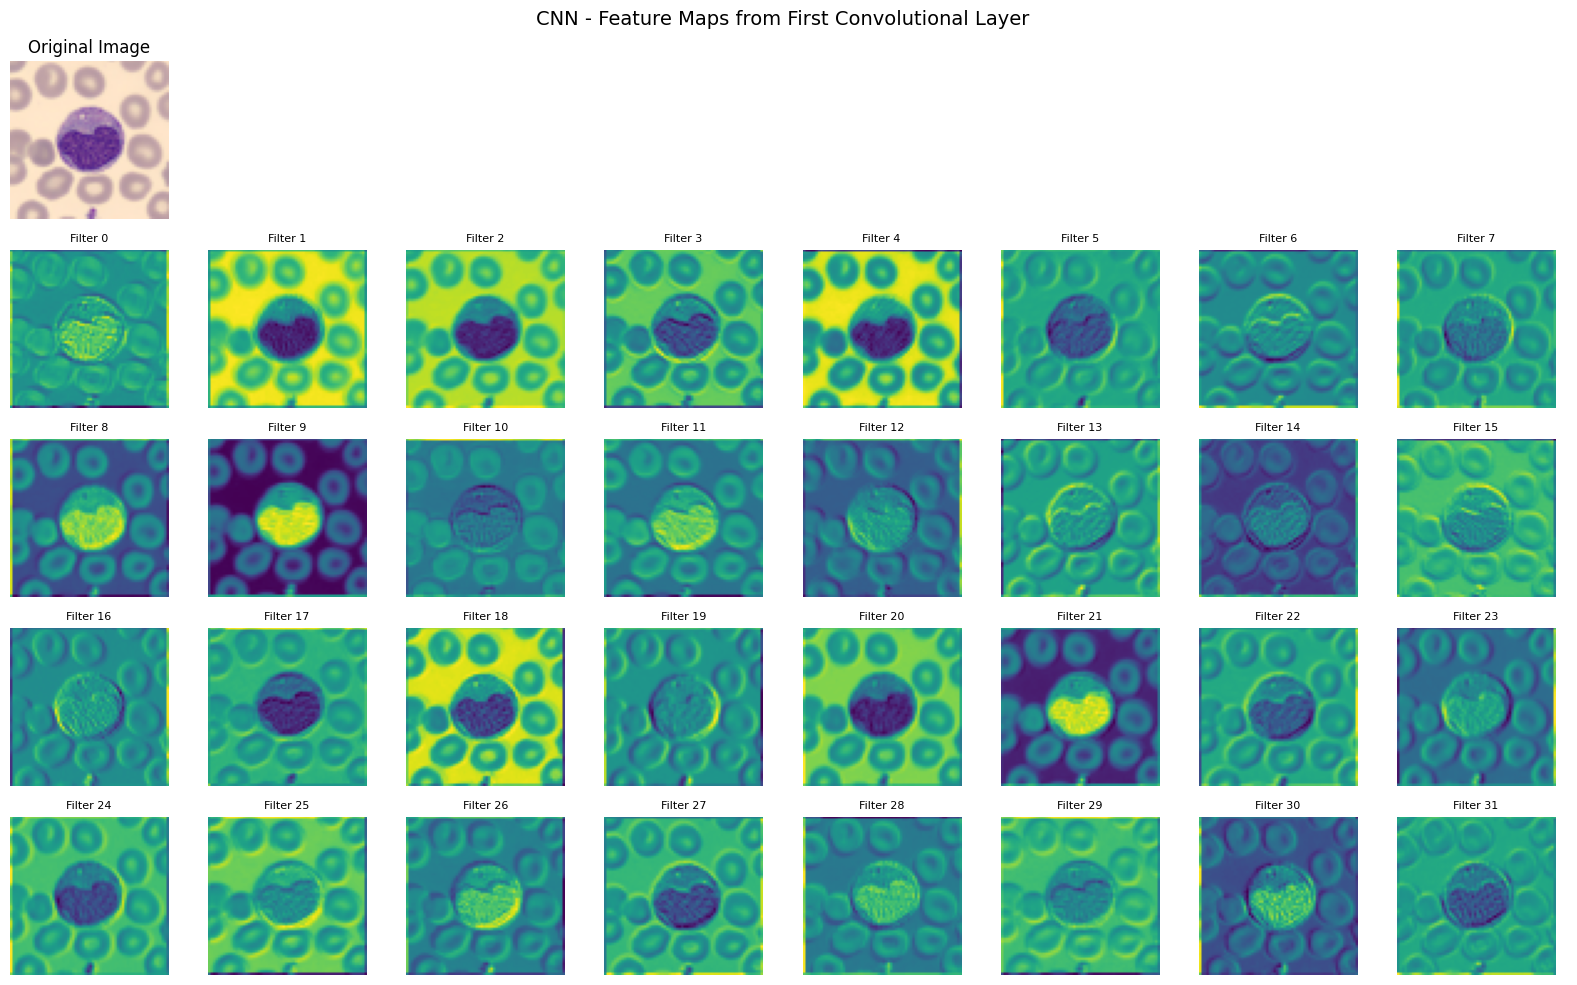

In [23]:
def visualize_feature_maps(model, image, class_names, title="CNN"):
    """
    Visualize feature maps from the first convolutional layer.
    Clips the model to only the first conv layer and passes an image through it.
    """
    model.eval()
    
    # Access the first conv layer
    # For our CNN, the conv layers are in model.conv_layers
    first_conv = model.conv_layers[0]  # First Conv2d layer
    
    # Forward pass through first conv layer only
    with torch.no_grad():
        input_tensor = image.unsqueeze(0).to(device)
        feature_maps = first_conv(input_tensor)
    
    feature_maps = feature_maps.squeeze(0).cpu().numpy()
    
    # Show original image
    img_display = inv_normalize(image).permute(1, 2, 0).numpy()
    img_display = np.clip(img_display, 0, 1)
    
    num_filters = feature_maps.shape[0]
    ncols = 8
    nrows = (num_filters + ncols - 1) // ncols
    
    fig, axes = plt.subplots(nrows + 1, ncols, figsize=(2 * ncols, 2 * (nrows + 1)))
    fig.suptitle(f'{title} - Feature Maps from First Convolutional Layer', fontsize=14)
    
    # Show original image in top-left
    axes[0, 0].imshow(img_display)
    axes[0, 0].set_title('Original Image')
    axes[0, 0].axis('off')
    
    # Clear remaining axes in first row
    for j in range(1, ncols):
        axes[0, j].axis('off')
    
    # Show feature maps
    for i in range(num_filters):
        row = (i // ncols) + 1
        col = i % ncols
        axes[row, col].imshow(feature_maps[i], cmap='viridis')
        axes[row, col].axis('off')
        axes[row, col].set_title(f'Filter {i}', fontsize=8)
    
    # Clear remaining empty axes
    for i in range(num_filters, nrows * ncols):
        row = (i // ncols) + 1
        col = i % ncols
        axes[row, col].axis('off')
    
    plt.tight_layout()
    plt.show()

# Select a random test image
random_idx = np.random.randint(len(mlp_images))
sample_image = mlp_images[random_idx]
sample_label = mlp_true[random_idx]
print(f'Visualization for class: {class_names[sample_label]}')

# Visualize CNN feature maps
visualize_feature_maps(cnn_model, sample_image, class_names, title="CNN")

**Analysis**: The first convolutional layer typically detects low-level features like edges, textures, and color gradients. Different filters respond to different patterns - some capture vertical edges, others horizontal edges, color transitions, or blob-like structures. This hierarchical feature extraction is what makes CNNs so powerful for image tasks.

---
## Part 5: Spatial Invariance Test (Rotation + Translation)

In [24]:
def find_correct_sample(models, test_loader, class_names):
    """
    Find one correctly classified sample per class that BOTH models predict correctly.
    Returns dict: class_idx -> (image_tensor, true_label)
    """
    correct_per_class = {i: [] for i in range(len(class_names))}
    
    all_preds = []
    all_labels = []
    all_images = []
    
    for model in models:
        model.eval()
    
    with torch.no_grad():
        for images, labels in test_loader:
            images = images.to(device)
            all_images.extend(images.cpu())
            all_labels.extend(labels.numpy())
            
            batch_preds = []
            for model in models:
                outputs = model(images)
                _, preds = torch.max(outputs, 1)
                batch_preds.append(preds.cpu().numpy())
            
            for i in range(len(labels)):
                class_idx = labels[i].item()
                # Check if ALL models predict correctly
                all_correct = all(bp[i] == class_idx for bp in batch_preds)
                if all_correct and len(correct_per_class[class_idx]) < 10:
                    correct_per_class[class_idx].append(i)
    
    # Select one per class
    result = {}
    for class_idx in range(len(class_names)):
        if correct_per_class[class_idx]:
            chosen_idx = np.random.choice(correct_per_class[class_idx])
            result[class_idx] = (all_images[chosen_idx], all_labels[chosen_idx])
    
    return result

correct_samples = find_correct_sample([mlp_model, cnn_model], test_loader, class_names)
print(f'Found correctly classified samples for {len(correct_samples)} classes')

Found correctly classified samples for 5 classes



Class: basophil


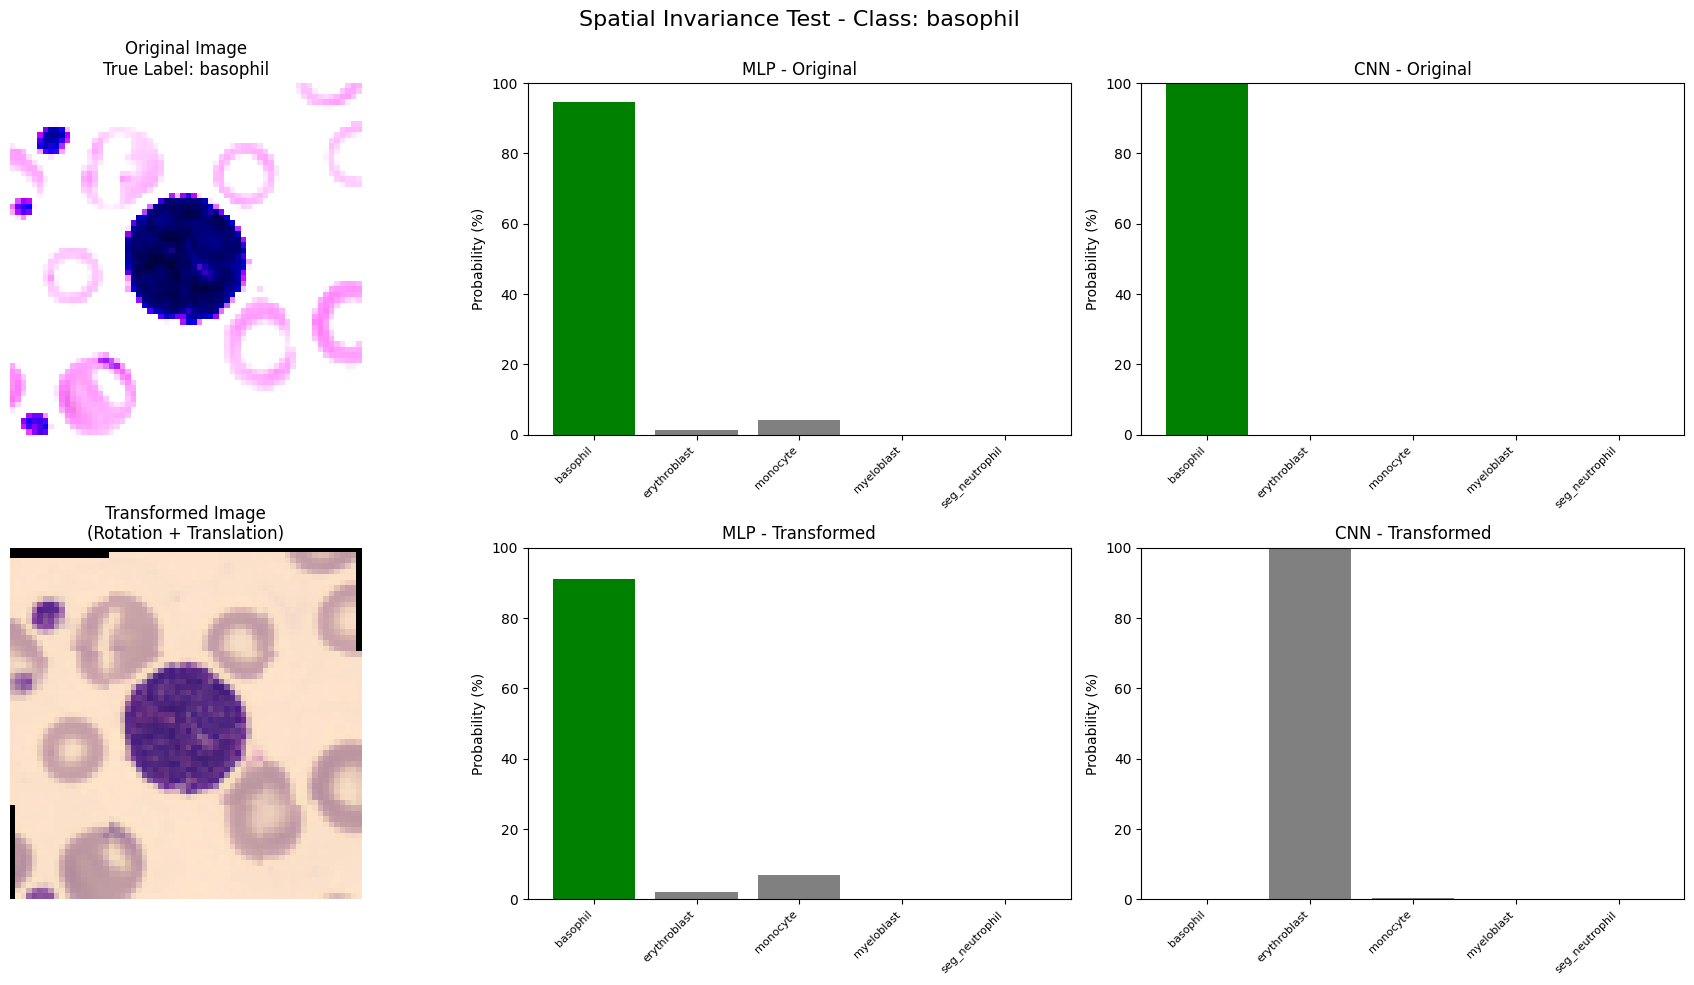

  MLP: Original -> basophil (94.5%) | Transformed -> basophil (91.0%)
  CNN: Original -> basophil (100.0%) | Transformed -> erythroblast (99.7%)

Class: erythroblast


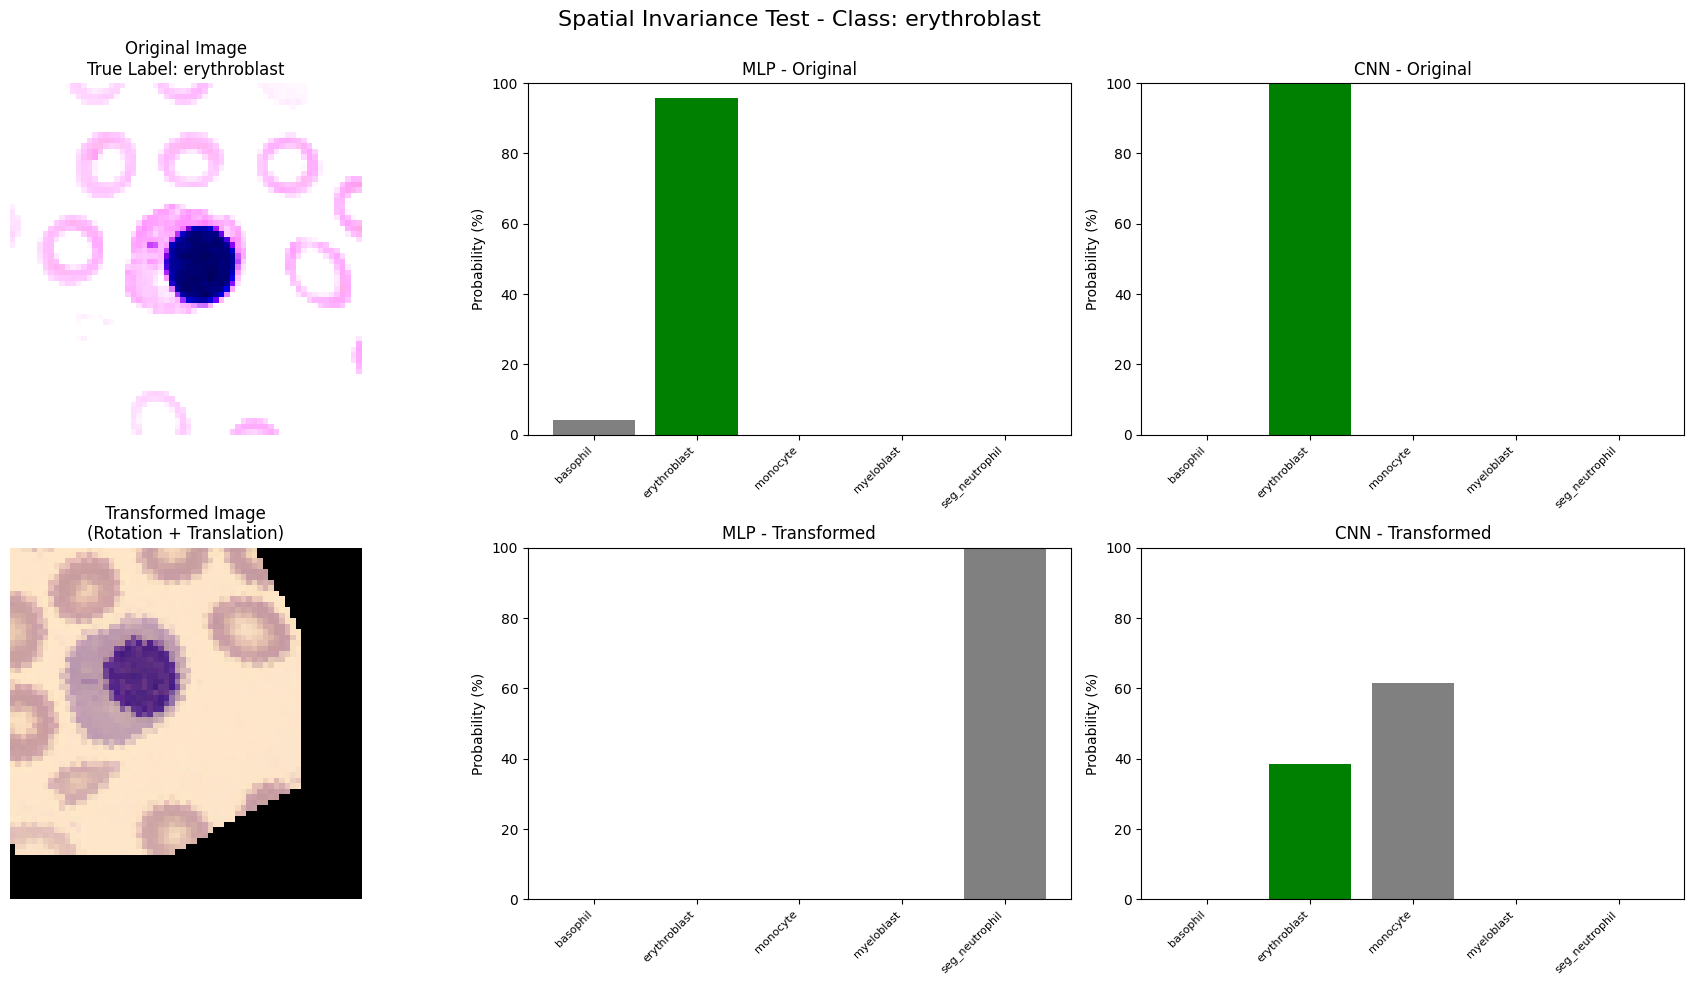

  MLP: Original -> erythroblast (95.8%) | Transformed -> seg_neutrophil (99.9%)
  CNN: Original -> erythroblast (100.0%) | Transformed -> monocyte (61.5%)

Class: monocyte


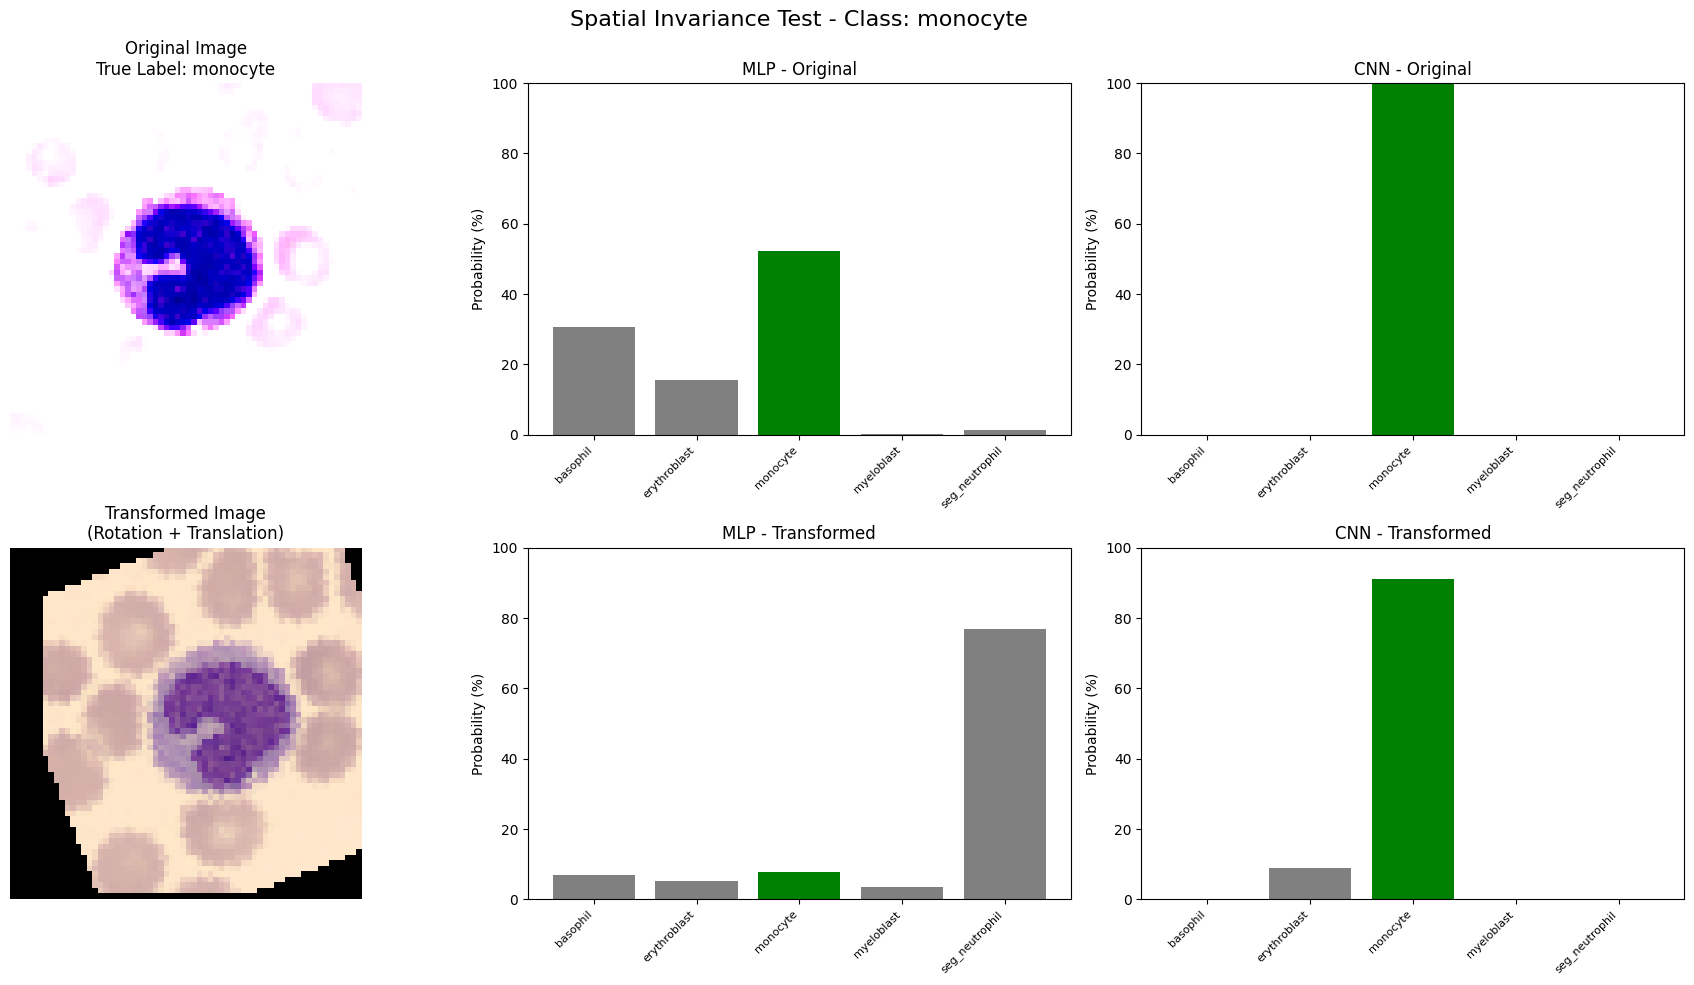

  MLP: Original -> monocyte (52.2%) | Transformed -> seg_neutrophil (76.8%)
  CNN: Original -> monocyte (100.0%) | Transformed -> monocyte (91.1%)

Class: erythroblast


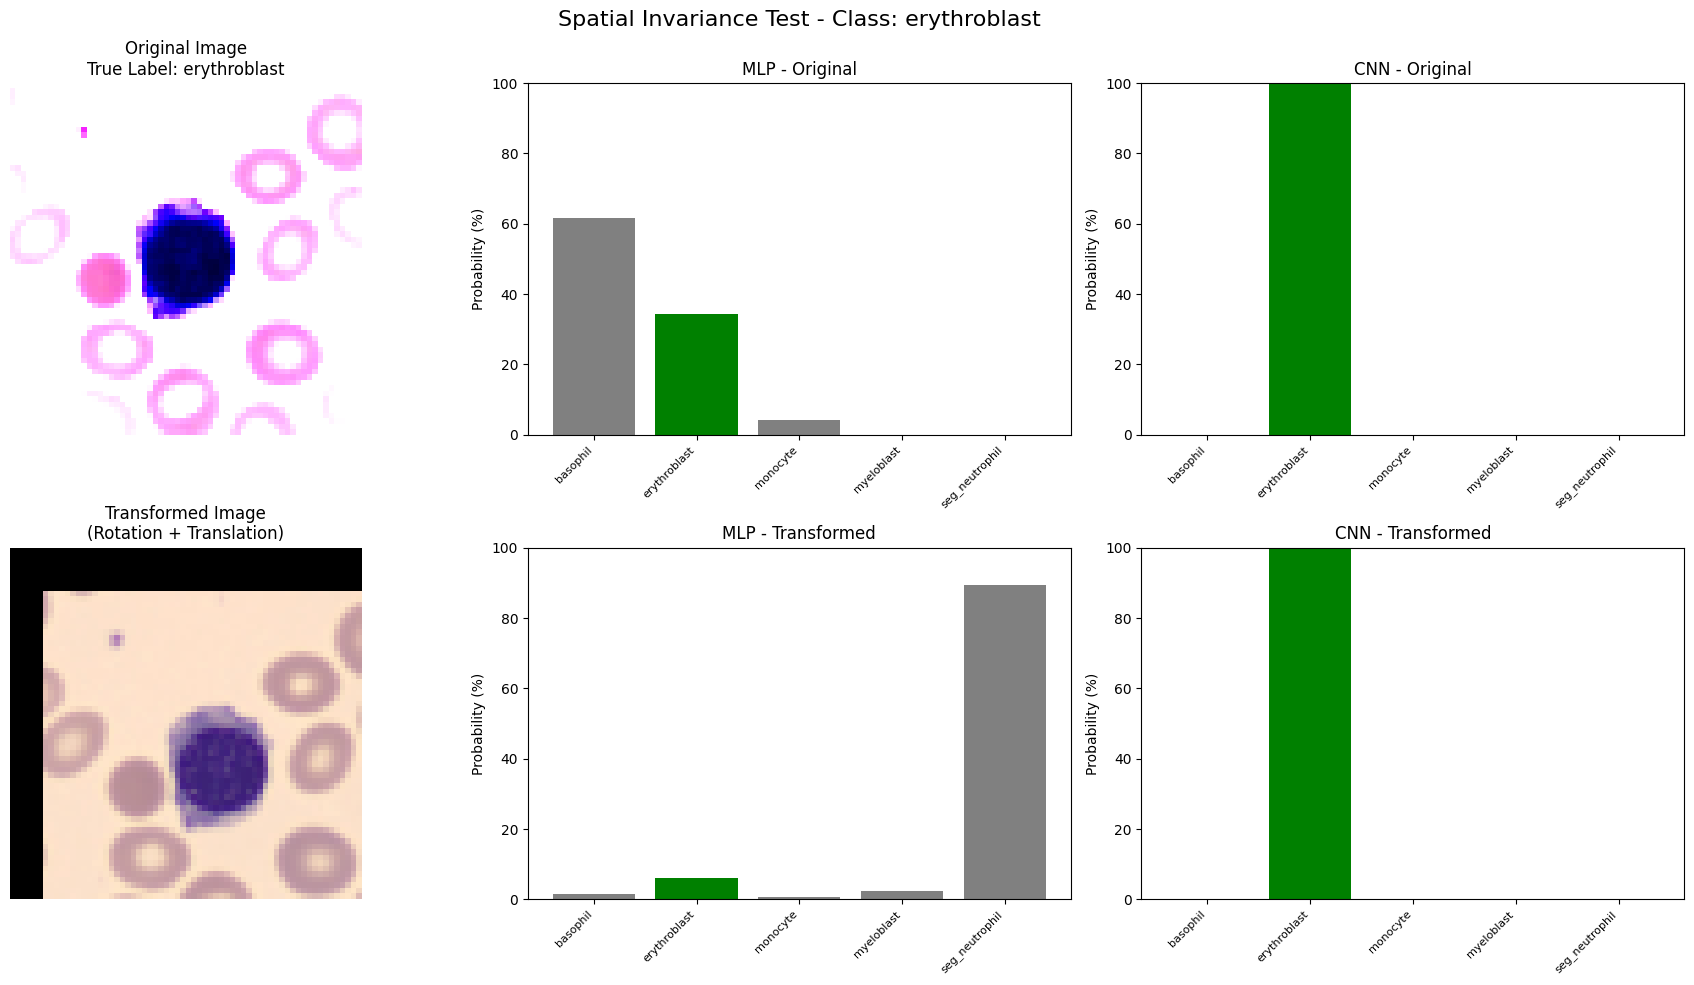

  MLP: Original -> basophil (61.5%) | Transformed -> seg_neutrophil (89.3%)
  CNN: Original -> erythroblast (100.0%) | Transformed -> erythroblast (100.0%)

Class: monocyte


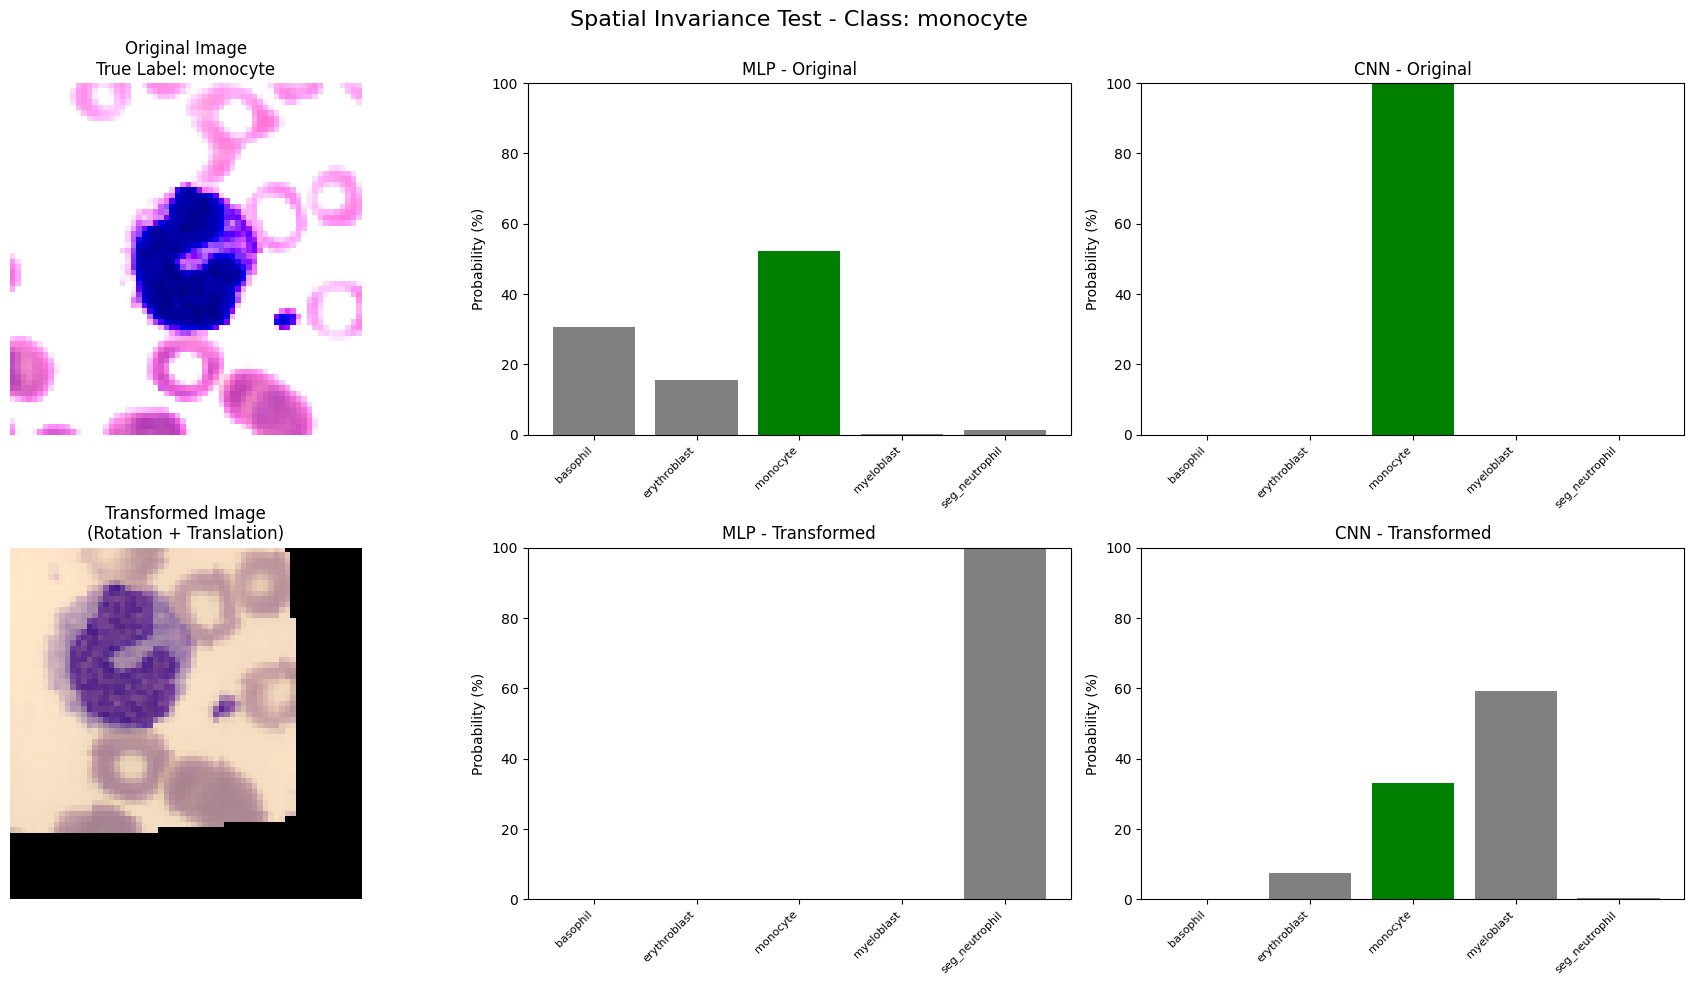

  MLP: Original -> monocyte (52.2%) | Transformed -> seg_neutrophil (100.0%)
  CNN: Original -> monocyte (100.0%) | Transformed -> myeloblast (59.1%)


In [25]:
# Spatial transformation: rotation + translation
spatial_transform = transforms.Compose([
    transforms.RandomRotation(degrees=30),
    transforms.RandomAffine(degrees=0, translate=(0.2, 0.2)),
])

def get_prediction_distributions(model, image):
    """Get softmax prediction distribution for a single image."""
    model.eval()
    with torch.no_grad():
        output = model(image.unsqueeze(0).to(device))
        probs = torch.softmax(output, dim=1).cpu().numpy()[0]
    return probs

for class_idx, (image, true_label) in correct_samples.items():
    print(f'\nClass: {class_names[true_label]}')
    
    # Apply spatial transformation
    # We need to work with unnormalized image for spatial transform,
    # then re-normalize for model input
    img_unnorm = inv_normalize(image)
    img_unnorm = torch.clamp(img_unnorm, 0, 1)
    
    # Apply transform
    img_transformed = spatial_transform(img_unnorm)
    # Re-normalize
    img_transformed_norm = basic_transform.transforms[-1](img_transformed)
    
    # Get predictions
    orig_mlp = get_prediction_distributions(mlp_model, image)
    orig_cnn = get_prediction_distributions(cnn_model, image)
    trans_mlp = get_prediction_distributions(mlp_model, img_transformed_norm)
    trans_cnn = get_prediction_distributions(cnn_model, img_transformed_norm)
    
    # Create figure
    fig, axes = plt.subplots(2, 3, figsize=(18, 10))
    fig.suptitle(f'Spatial Invariance Test - Class: {class_names[true_label]}', fontsize=16)
    
    # Row 1: Original image
    orig_display = image.permute(1, 2, 0).numpy()
    orig_display = np.clip(orig_display, 0, 1)
    axes[0, 0].imshow(orig_display)
    axes[0, 0].set_title(f'Original Image\nTrue Label: {class_names[true_label]}')
    axes[0, 0].axis('off')
    
    # MLP predictions for original
    colors = ['green' if j == true_label else 'gray' for j in range(NUM_CLASSES)]
    axes[0, 1].bar(range(NUM_CLASSES), orig_mlp * 100, color=colors)
    axes[0, 1].set_xticks(range(NUM_CLASSES))
    axes[0, 1].set_xticklabels(class_names, rotation=45, ha='right', fontsize=8)
    axes[0, 1].set_title('MLP - Original')
    axes[0, 1].set_ylabel('Probability (%)')
    axes[0, 1].set_ylim(0, 100)
    
    # CNN predictions for original
    axes[0, 2].bar(range(NUM_CLASSES), orig_cnn * 100, color=colors)
    axes[0, 2].set_xticks(range(NUM_CLASSES))
    axes[0, 2].set_xticklabels(class_names, rotation=45, ha='right', fontsize=8)
    axes[0, 2].set_title('CNN - Original')
    axes[0, 2].set_ylabel('Probability (%)')
    axes[0, 2].set_ylim(0, 100)
    
    # Row 2: Transformed image
    trans_display = img_transformed.permute(1, 2, 0).numpy()
    trans_display = np.clip(trans_display, 0, 1)
    axes[1, 0].imshow(trans_display)
    axes[1, 0].set_title('Transformed Image\n(Rotation + Translation)')
    axes[1, 0].axis('off')
    
    # MLP predictions for transformed
    axes[1, 1].bar(range(NUM_CLASSES), trans_mlp * 100, color=colors)
    axes[1, 1].set_xticks(range(NUM_CLASSES))
    axes[1, 1].set_xticklabels(class_names, rotation=45, ha='right', fontsize=8)
    axes[1, 1].set_title('MLP - Transformed')
    axes[1, 1].set_ylabel('Probability (%)')
    axes[1, 1].set_ylim(0, 100)
    
    # CNN predictions for transformed
    axes[1, 2].bar(range(NUM_CLASSES), trans_cnn * 100, color=colors)
    axes[1, 2].set_xticks(range(NUM_CLASSES))
    axes[1, 2].set_xticklabels(class_names, rotation=45, ha='right', fontsize=8)
    axes[1, 2].set_title('CNN - Transformed')
    axes[1, 2].set_ylabel('Probability (%)')
    axes[1, 2].set_ylim(0, 100)
    
    plt.tight_layout()
    plt.show()
    
    # Print analysis
    orig_mlp_pred = np.argmax(orig_mlp)
    trans_mlp_pred = np.argmax(trans_mlp)
    orig_cnn_pred = np.argmax(orig_cnn)
    trans_cnn_pred = np.argmax(trans_cnn)
    
    print(f'  MLP: Original -> {class_names[orig_mlp_pred]} ({orig_mlp[orig_mlp_pred]*100:.1f}%)'
          f' | Transformed -> {class_names[trans_mlp_pred]} ({trans_mlp[trans_mlp_pred]*100:.1f}%)')
    print(f'  CNN: Original -> {class_names[orig_cnn_pred]} ({orig_cnn[orig_cnn_pred]*100:.1f}%)'
          f' | Transformed -> {class_names[trans_cnn_pred]} ({trans_cnn[trans_cnn_pred]*100:.1f}%)')

### Spatial Invariance Analysis

**CNN outperforms MLP** in handling geometric transformations because:
1. **Weight sharing**: Convolutional filters are applied across all spatial locations, making them inherently position-invariant
2. **Local connectivity**: Each neuron only connects to a local patch, allowing the same feature to be detected anywhere
3. **Pooling layers**: Max pooling provides translation invariance by taking the maximum value in a region
4. **MLP limitation**: Fully connected layers treat each pixel independently at fixed positions, so spatial shifts disrupt the learned patterns completely

---
## Part 6: Sensitivity Analysis (Occlusion Sensitivity Heatmap)

In [26]:
def occlusion_sensitivity(model, image, true_label, patch_size=8, mean_value=None):
    """
    Compute occlusion sensitivity heatmap.
    For each patch position, occlude the region and measure the drop in
    probability for the true class.
    
    Args:
        model: trained model
        image: single image tensor (C, H, W)
        true_label: ground truth class index
        patch_size: size of occlusion patch
        mean_value: value to fill occluded region (None = image mean)
    
    Returns:
        heatmap: 2D array of probability drops
    """
    model.eval()
    H, W = image.shape[1], image.shape[2]
    
    if mean_value is None:
        mean_value = image.mean().item()
    
    # Get original prediction
    with torch.no_grad():
        output = model(image.unsqueeze(0).to(device))
        orig_prob = torch.softmax(output, dim=1)[0, true_label].item()
    
    heatmap = np.zeros((H, W))
    
    for i in range(0, H - patch_size + 1):
        for j in range(0, W - patch_size + 1):
            # Create occluded image
            occluded = image.clone()
            occluded[:, i:i+patch_size, j:j+patch_size] = mean_value
            
            # Get prediction on occluded image
            with torch.no_grad():
                output = model(occluded.unsqueeze(0).to(device))
                occ_prob = torch.softmax(output, dim=1)[0, true_label].item()
            
            # Record probability drop
            drop = orig_prob - occ_prob
            heatmap[i:i+patch_size, j:j+patch_size] = np.maximum(
                heatmap[i:i+patch_size, j:j+patch_size], drop
            )
    
    return heatmap, orig_prob

print('Occlusion sensitivity function defined.')

Occlusion sensitivity function defined.


Visualizing for class: basophil
Computing MLP heatmap... (this may take a moment)
Computing CNN heatmap... (this may take a moment)


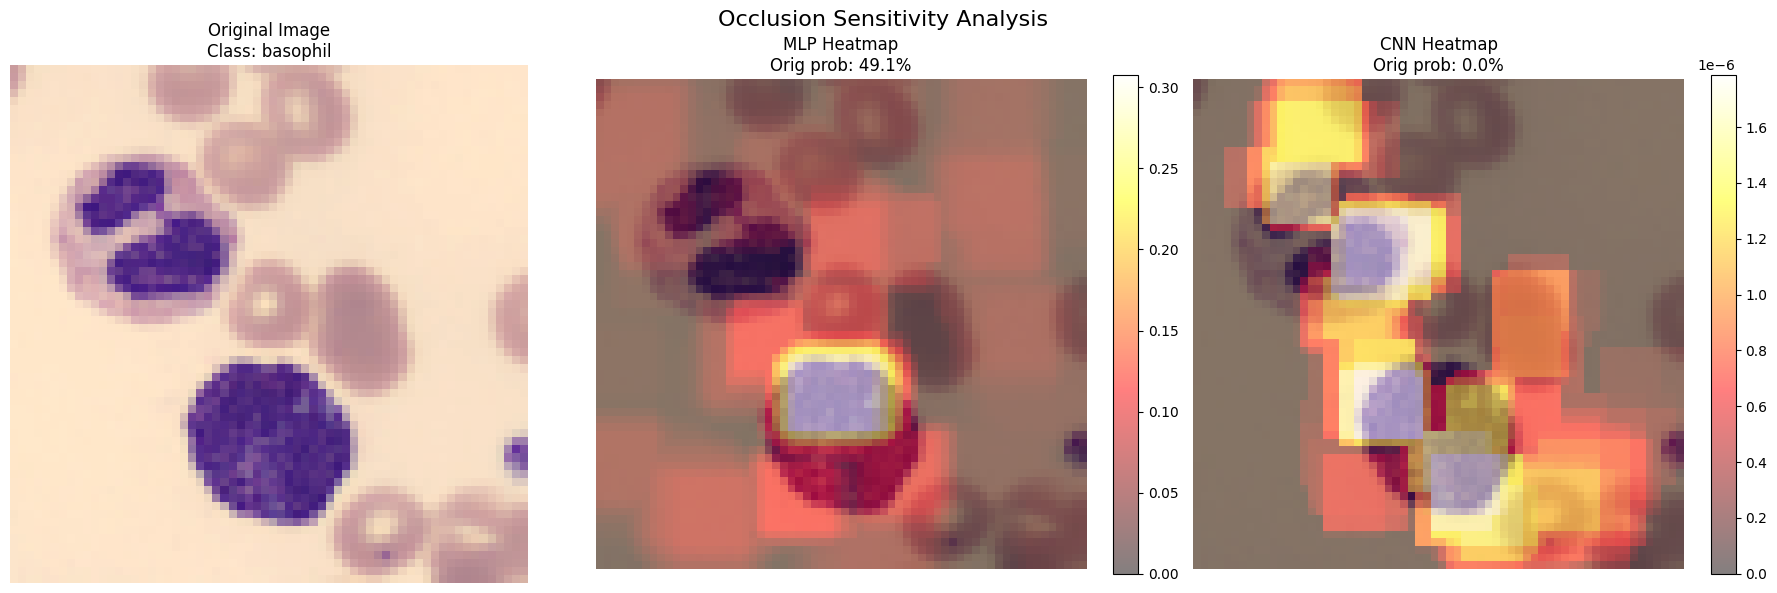


MLP original probability: 49.14%
CNN original probability: 0.00%
MLP max drop: 30.79%
CNN max drop: 0.00%


In [27]:
# Select one random test image
np.random.seed(42)
vis_idx = np.random.randint(len(mlp_images))
vis_image = mlp_images[vis_idx]
vis_label = mlp_true[vis_idx]

print(f'Visualizing for class: {class_names[vis_label]}')

# Compute occlusion sensitivity for both models
print('Computing MLP heatmap... (this may take a moment)')
mlp_heatmap, mlp_orig_prob = occlusion_sensitivity(mlp_model, vis_image, vis_label, patch_size=8)

print('Computing CNN heatmap... (this may take a moment)')
cnn_heatmap, cnn_orig_prob = occlusion_sensitivity(cnn_model, vis_image, vis_label, patch_size=8)

# Display results
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
fig.suptitle('Occlusion Sensitivity Analysis', fontsize=16)

# Original image
orig_display = inv_normalize(vis_image).permute(1, 2, 0).numpy()
orig_display = np.clip(orig_display, 0, 1)
axes[0].imshow(orig_display)
axes[0].set_title(f'Original Image\nClass: {class_names[vis_label]}')
axes[0].axis('off')

# MLP heatmap overlay
axes[1].imshow(orig_display)
im1 = axes[1].imshow(mlp_heatmap, cmap='hot', alpha=0.5)
axes[1].set_title(f'MLP Heatmap\nOrig prob: {mlp_orig_prob*100:.1f}%')
axes[1].axis('off')
plt.colorbar(im1, ax=axes[1], fraction=0.046)

# CNN heatmap overlay
axes[2].imshow(orig_display)
im2 = axes[2].imshow(cnn_heatmap, cmap='hot', alpha=0.5)
axes[2].set_title(f'CNN Heatmap\nOrig prob: {cnn_orig_prob*100:.1f}%')
axes[2].axis('off')
plt.colorbar(im2, ax=axes[2], fraction=0.046)

plt.tight_layout()
plt.show()

print(f'\nMLP original probability: {mlp_orig_prob*100:.2f}%')
print(f'CNN original probability: {cnn_orig_prob*100:.2f}%')
print(f'MLP max drop: {mlp_heatmap.max()*100:.2f}%')
print(f'CNN max drop: {cnn_heatmap.max()*100:.2f}%')

### Sensitivity Analysis

The heatmap shows which regions are most important for the model's prediction:
- **Hot regions (high drop)**: Areas the model relies on heavily for classification. If these are biological structures (cell nuclei, cytoplasm), the model learned meaningful features.
- **CNN vs MLP**: CNN heatmaps typically focus on cell-specific regions (nuclei, cell boundaries), while MLP heatmaps may be more scattered since MLP cannot leverage spatial structure.
- If the model focuses on background noise rather than cell structures, it indicates the model may not have learned biologically meaningful features.